# 11. Обработка выбросов

Рабочий ноутбук к главе книги `../chapters/11-outliers.md`: здесь только задания и код, теория и выводы — в главе. Источник — глава 17 пособия.

Графики для главы сохраняй через `save_fig(fig, "имя")` → `../chapters/img/11-имя.png`.

In [1]:
import logging
import os
import warnings
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Глушим шум до импорта ETNA: FutureWarning из pandas и предупреждение tqdm про ipywidgets
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

from etna.datasets import TSDataset
from etna.models import ProphetModel
from etna.transforms import IQROutlierTransform, TimeSeriesImputerTransform
from etna.analysis import (
    get_anomalies_median,
    get_anomalies_density,
    get_anomalies_hist,
    get_anomalies_isolation_forest,
    get_anomalies_iqr,
    get_anomalies_prediction_interval,
    plot_anomalies,
)

logging.getLogger("cmdstanpy").disabled = True  # Prophet пишет в лог на каждом fit()

IMG_DIR = "../chapters/img"  # графики для главы книги
RANDOM_SEED = 42


def save_fig(fig, name: str) -> None:
    """Сохранить график для главы книги: ../chapters/img/11-<name>.png."""
    os.makedirs(IMG_DIR, exist_ok=True)
    fig.savefig(f"{IMG_DIR}/11-{name}.png", dpi=150, bbox_inches="tight")

## Задание 1. Синтетика: найти и убрать выбросы

Ряд, в котором мы знаем, где выбросы и какими были правильные значения.

### Шаг 1.1. Ряд с выбросами

Синтетический ряд с недельной сезонностью и 6 выбросами в известных местах: 4 глобальных (резко выше или ниже всего ряда) и 2 контекстных (обычное значение, но не для своего дня недели).

,day_of_week,kind,clean,with_outlier
2026-01-21,Wednesday,глобальный,164.0,244.0
2026-02-08,Sunday,глобальный,121.0,51.0
2026-04-01,Wednesday,глобальный,160.0,200.0
2026-04-14,Tuesday,глобальный,148.0,238.0
2026-02-25,Wednesday,контекстный,163.0,118.0
2026-03-12,Thursday,контекстный,111.0,156.0


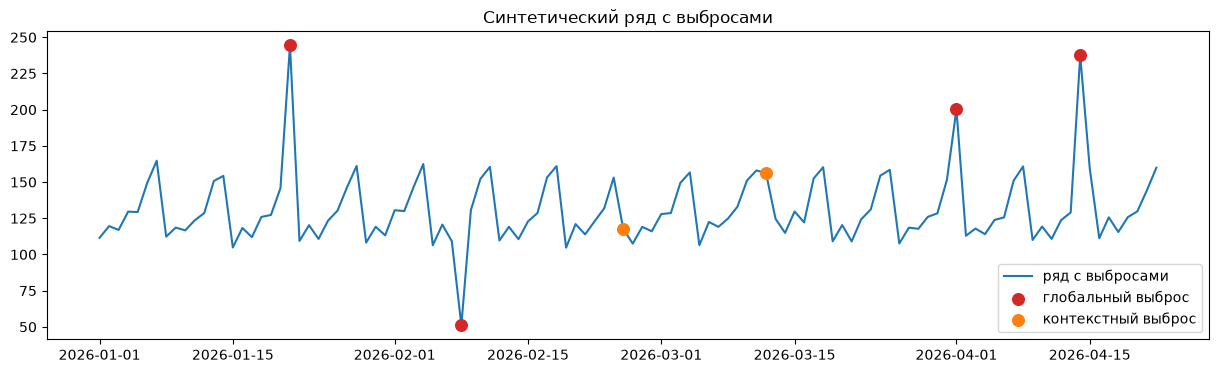

In [2]:
# Ряд как в главе про импутацию: 16 недель, недельный узор, шум ±3. Правильные значения сохраняем
DAY_OF_WEEK_PATTERN = np.array([10, 20, 15, 25, 30, 50, 60], dtype=float)
PERIODS = 16 * 7

rng = np.random.RandomState(RANDOM_SEED)
timestamps = pd.date_range("2026-01-01", periods=PERIODS, freq="D")
clean_values = pd.Series(100 + np.tile(DAY_OF_WEEK_PATTERN, PERIODS // 7) + rng.normal(0, 3, PERIODS), index=timestamps)

# Выбросы двух видов: глобальные (резко выше или ниже всего ряда) и контекстные —
# значение обычное для ряда в целом, но необычное для своего дня недели
peak_days = [d for d in range(PERIODS) if DAY_OF_WEEK_PATTERN[d % 7] == 60]  # самый сильный день недели
low_days = [d for d in range(PERIODS) if DAY_OF_WEEK_PATTERN[d % 7] == 10]   # самый слабый день недели
OUTLIERS = {  # номер дня → (сдвиг, вид)
    20: (+80, "глобальный"),
    38: (-70, "глобальный"),
    90: (+40, "глобальный"),
    103: (+90, "глобальный"),
    peak_days[7]: (-45, "контекстный"),   # провал в самый сильный день → значение как в обычный день
    low_days[10]: (+45, "контекстный"),   # всплеск в самый слабый день → значение как в обычный день
}

values = clean_values.copy()
for day, (shift, _) in OUTLIERS.items():
    values.iloc[day] += shift
outlier_kind = pd.Series({timestamps[day]: kind for day, (_, kind) in OUTLIERS.items()})

ts = TSDataset(pd.DataFrame({"timestamp": timestamps, "segment": "synthetic", "target": values.values}), freq="D")

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(values.index, values.values, color="C0", label="ряд с выбросами")
for kind, color in [("глобальный", "C3"), ("контекстный", "C1")]:
    days = outlier_kind[outlier_kind == kind].index
    ax.scatter(days, values[days], s=70, color=color, zorder=3, label=f"{kind} выброс")
ax.legend(loc="lower right")
ax.set_title("Синтетический ряд с выбросами")
save_fig(fig, "outliers")

pd.DataFrame({
    "day_of_week": outlier_kind.index.day_name(),
    "kind": outlier_kind.values,
    "clean": clean_values[outlier_kind.index].round(),
    "with_outlier": values[outlier_kind.index].round(),
}, index=outlier_kind.index.date)

#### Выводы

- Ряд тот же, что в главе про пропуски: 16 недель, недельный узор (самый сильный день на 50 заказов больше самого слабого) и шум ±3. Правильные значения сохранены.
- Выбросов 6 двух видов:
  - **4 глобальных** — резко выше или ниже всего ряда: 244, 51, 200, 238 при обычных 110–165;
  - **2 контекстных** — значение обычное для ряда в целом, но необычное для своего дня недели: в самый сильный день вместо ~163 стало 118, в самый слабый вместо ~111 стало 156. Оба значения сами по себе лежат внутри обычного диапазона ряда.

### Шаг 1.2. Простые методы поиска

`get_anomalies_median`, `get_anomalies_density`, `get_anomalies_hist`, `get_anomalies_isolation_forest` — по умолчанию и с более чувствительными параметрами: сколько выбросов нашёл каждый и сколько лишних точек отметил.

In [3]:
def score(anomalies: dict) -> dict:
    """Сколько выбросов метод нашёл (всего и контекстных) и сколько лишних точек отметил."""
    found = set(pd.to_datetime(anomalies.get("synthetic", [])))
    true_all = set(outlier_kind.index)
    true_context = set(outlier_kind[outlier_kind == "контекстный"].index)
    return {
        "found": f"{len(found & true_all)}/{len(true_all)}",
        "found_context": f"{len(found & true_context)}/{len(true_context)}",
        "false": len(found - true_all),
    }


# Методы, которые смотрят только на значения — про недельный узор не знают
simple_methods = {
    "median": get_anomalies_median(ts),
    "median (window_size=7, alpha=2)": get_anomalies_median(ts, window_size=7, alpha=2),
    "density": get_anomalies_density(ts),
    "density (window_size=7, distance_coef=1, n_neighbors=2)": get_anomalies_density(ts, window_size=7, distance_coef=1, n_neighbors=2),
    "hist": get_anomalies_hist(ts),
    "isolation_forest": get_anomalies_isolation_forest(ts, random_state=RANDOM_SEED),
}
pd.DataFrame({name: score(result) for name, result in simple_methods.items()}).T

,found,found_context,false
median,2/6,0/2,0
"median (window_size=7, alpha=2)",4/6,0/2,6
density,2/6,0/2,0
"density (window_size=7, distance_coef=1, n_neighbors=2)",4/6,0/2,10
hist,4/6,0/2,3
isolation_forest,4/6,0/2,9


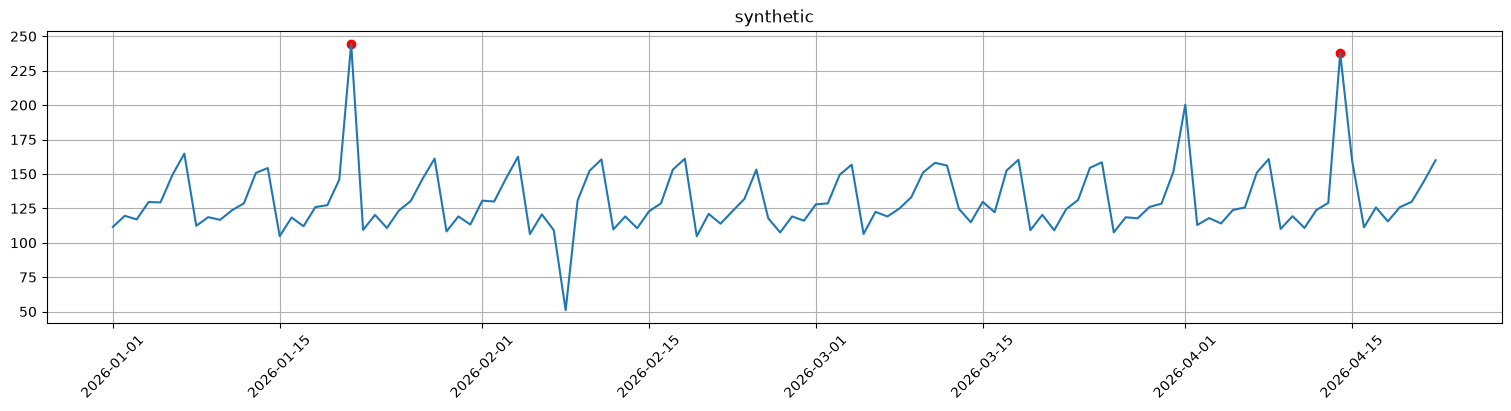

In [4]:
# Что нашёл медианный метод с параметрами по умолчанию
plot_anomalies(ts, simple_methods["median"], figsize=(15, 4))

#### Выводы

| метод | нашёл из 6 | контекстных из 2 | лишних точек |
|---|---|---|---|
| `median` (по умолчанию) | 2 | 0 | 0 |
| `median` (`window_size=7`, `alpha=2`) | 4 | 0 | 6 |
| `density` (по умолчанию) | 2 | 0 | 0 |
| `density` (чувствительнее) | 4 | 0 | 10 |
| `hist` | 4 | 0 | 3 |
| `isolation_forest` | 4 | 0 | 9 |

- **Контекстные выбросы не нашёл ни один простой метод.** Эти методы смотрят на значение, а не на то, какой сейчас день недели. Провал до 118 в самый сильный день для них — обычный будний день.
- **По умолчанию методы осторожные:** находят только самые резкие выбросы (2 из 6), зато без лишних точек.
- **Сделать их чувствительнее — значит получить лишние точки.** `median` и `density` с более строгими параметрами нашли 4 выброса, но заодно отметили 6–10 обычных дней, в основном недельные пики. Это общий компромисс: «найти больше» = «больше ложных тревог».

### Шаг 1.3. Методы с учётом сезонности

`get_anomalies_iqr` с `seasonality=True` (окно 28 и 112 дней) и `get_anomalies_prediction_interval` с `ProphetModel`; где лежат лишние точки.

In [5]:
# Методы, которые учитывают сезонность: IQR после удаления сезонности (STL) и интервал прогноза Prophet
seasonal_methods = {
    "iqr (seasonality=True, window_size=28)": get_anomalies_iqr(ts, window_size=28, seasonality=True, period=7, iqr_scale=3),
    "iqr (seasonality=True, window_size=112)": get_anomalies_iqr(ts, window_size=112, seasonality=True, period=7, iqr_scale=3),
    "prediction_interval (ProphetModel)": get_anomalies_prediction_interval(ts, model=ProphetModel, interval_width=0.95),
}
pd.DataFrame({name: score(result) for name, result in seasonal_methods.items()}).T

,found,found_context,false
"iqr (seasonality=True, window_size=28)",6/6,2/2,12
"iqr (seasonality=True, window_size=112)",6/6,2/2,1
prediction_interval (ProphetModel),6/6,2/2,0


дней до ближайшего выброса: [7, 7, 7, 7, 7, 7, 7, 7, 7, 6, 6, 7]


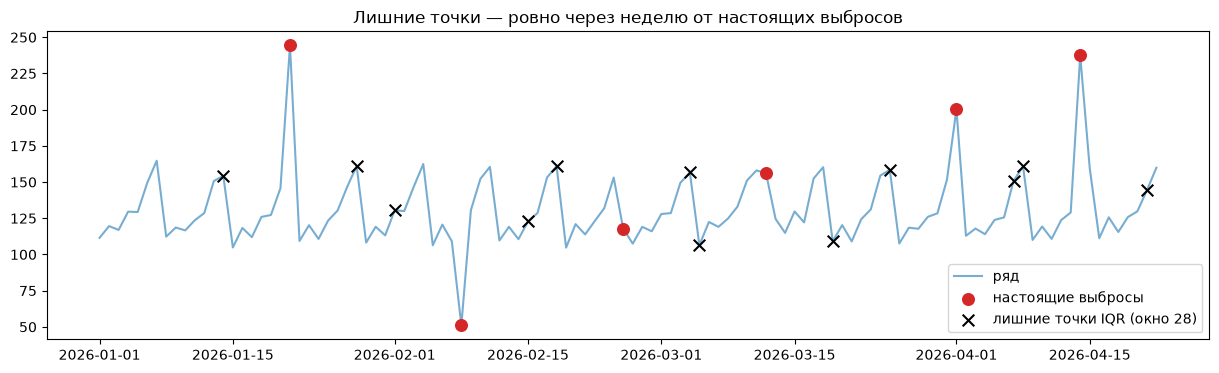

In [6]:
# Где лежат лишние точки IQR с узким окном: сколько дней до ближайшего настоящего выброса
narrow = set(pd.to_datetime(seasonal_methods["iqr (seasonality=True, window_size=28)"]["synthetic"]))
false_days = sorted(narrow - set(outlier_kind.index))
days_to_outlier = [min(abs((day - true).days) for true in outlier_kind.index) for day in false_days]
print("дней до ближайшего выброса:", days_to_outlier)

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(values.index, values.values, color="C0", alpha=0.6, label="ряд")
ax.scatter(outlier_kind.index, values[outlier_kind.index], s=70, color="C3", zorder=3, label="настоящие выбросы")
ax.scatter(false_days, values[false_days], s=70, marker="x", color="black", zorder=4, label="лишние точки IQR (окно 28)")
ax.legend(loc="lower right")
ax.set_title("Лишние точки — ровно через неделю от настоящих выбросов")
save_fig(fig, "iqr-echo")

#### Выводы

| метод | нашёл из 6 | контекстных из 2 | лишних точек |
|---|---|---|---|
| `iqr` с сезонностью, окно 28 дней | 6 | 2 | 12 |
| `iqr` с сезонностью, окно 112 дней | 6 | 2 | 1 |
| `prediction_interval` (`ProphetModel`) | 6 | 2 | **0** |

- **Учёт сезонности решает проблему контекстных выбросов.** `iqr` с `seasonality=True` сначала убирает из ряда недельный узор и ищет выбросы в остатке — там провал в сильный день уже заметен. `prediction_interval` строит модель, прогнозирует каждый день и считает выбросом всё, что вышло за интервал прогноза.
- **У `iqr` с узким окном лишние точки — «эхо» выбросов:** все 12 лежат ровно через неделю от настоящих. При удалении сезонности выброс частично попадает в «сезонную норму» своего дня недели, и соседние недели в тот же день начинают выглядеть подозрительно. Окно на всю историю (112 дней) размывает это влияние — остаётся 1 лишняя точка.
- **`prediction_interval` с Prophet — лучший результат:** все 6 выбросов, ни одной лишней точки. Цена — нужно обучить модель, это дольше остальных методов.

### Шаг 1.4. Убрать и заполнить

`IQROutlierTransform` превращает выбросы в пропуски, `TimeSeriesImputerTransform` заполняет их; сравни с рядом без выбросов.

средняя ошибка на днях с выбросами: до 61.7, после 3.8


,clean,with_outlier,repaired,error_before,error_after
2026-01-21,164.4,244.4,159.5,80.0,4.9
2026-02-08,121.0,51.0,126.6,70.0,5.6
2026-04-01,160.3,200.3,158.9,40.0,1.4
2026-04-14,147.6,237.6,152.3,90.0,4.7
2026-02-25,162.8,117.8,161.3,45.0,1.5
2026-03-12,111.1,156.1,106.2,45.0,4.9


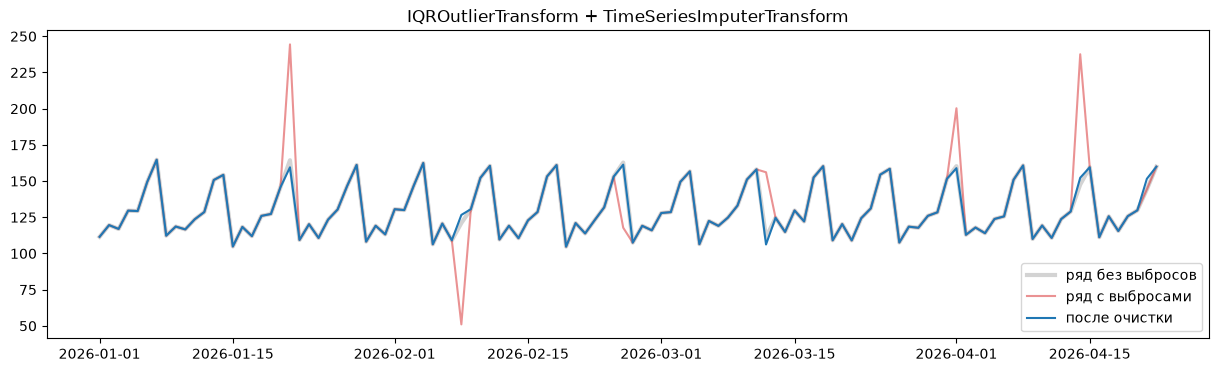

In [7]:
# Убираем выбросы и заполняем дыры: выбросы → NaN (IQROutlierTransform) → сезонная импутация (глава про пропуски)
ts_repaired = deepcopy(ts)
ts_repaired.fit_transform([
    IQROutlierTransform(in_column="target", window_size=112, seasonality=True, period=7, iqr_scale=3),
    TimeSeriesImputerTransform(in_column="target", strategy="seasonal", seasonality=7, window=3),
])
repaired = ts_repaired[:, "synthetic", "target"]

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(clean_values.index, clean_values.values, color="lightgrey", linewidth=3, label="ряд без выбросов")
ax.plot(values.index, values.values, color="C3", alpha=0.5, label="ряд с выбросами")
ax.plot(repaired.index, repaired.values, color="C0", label="после очистки")
ax.legend(loc="lower right")
ax.set_title("IQROutlierTransform + TimeSeriesImputerTransform")
save_fig(fig, "repaired")

repair_df = pd.DataFrame({
    "clean": clean_values[outlier_kind.index],
    "with_outlier": values[outlier_kind.index],
    "repaired": repaired[outlier_kind.index],
}, index=outlier_kind.index.date)
repair_df["error_before"] = (repair_df["with_outlier"] - repair_df["clean"]).abs()
repair_df["error_after"] = (repair_df["repaired"] - repair_df["clean"]).abs()
print(f"средняя ошибка на днях с выбросами: до {repair_df['error_before'].mean():.1f}, после {repair_df['error_after'].mean():.1f}")
repair_df.round(1)

#### Выводы

- **Очистка — это два трансформа подряд:** `IQROutlierTransform` превращает найденные выбросы в пропуски, `TimeSeriesImputerTransform` с сезонной стратегией их заполняет.
- **На днях с выбросами ошибка упала с 62 до 4 заказов** — на уровень шума. Заполненные значения легли почти на ряд без выбросов, недельный узор сохранился.
- **Цена лишних точек:** один обычный день, который `iqr` принял за выброс, тоже заменился сезонным средним и сдвинулся со 144 до 152 заказов. Правка небольшая, но ненужная — чем больше лишних точек у метода, тем больше настоящих данных он «причешет».